<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


Unique customerID: 7043
Duplicate customerID: 0

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

--- StreamingTV ---
StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

--- StreamingMovies ---
StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

--- PaperlessBilling ---
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64
(5634, 19)
(1409, 19)
(563

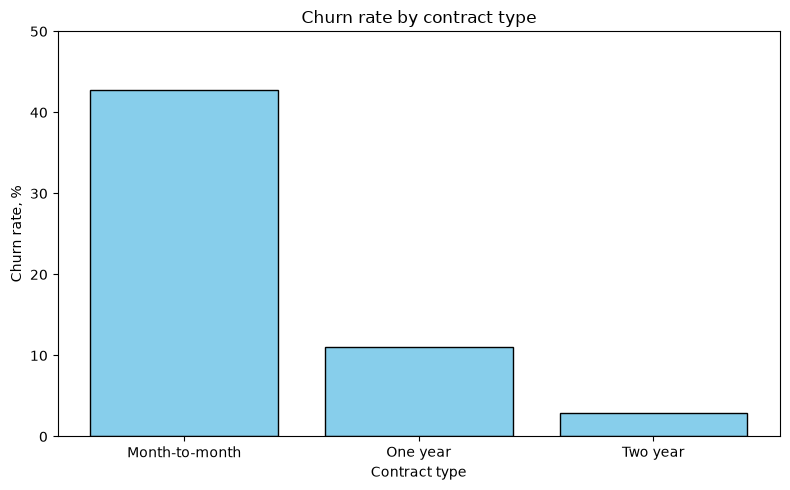

tenure_group
0–12     1737
13–24     818
25–36     669
37–48     621
49–60     658
61–72    1131
Name: count, dtype: int64
Total clients: 5634
Missing values in groups: 0
Churn               No       Yes
tenure_group                    
0–12          0.526770  0.473230
13–24         0.713936  0.286064
25–36         0.790732  0.209268
37–48         0.805153  0.194847
49–60         0.846505  0.153495
61–72         0.931919  0.068081


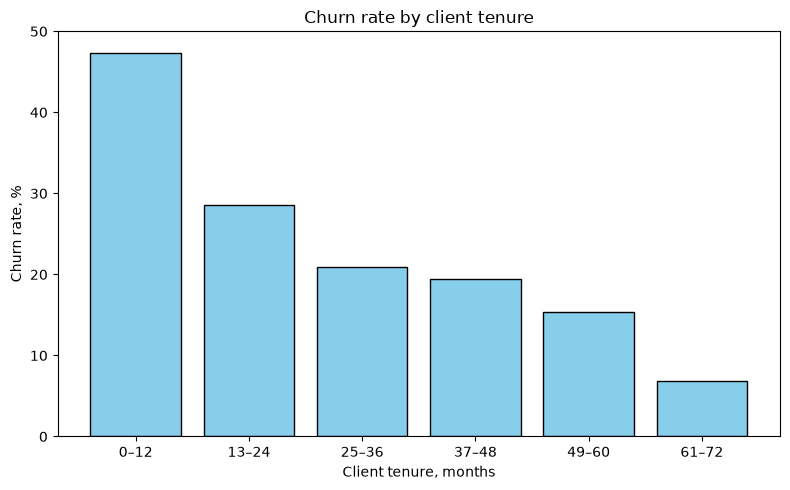

       count   mean  median    std
Churn                             
No      4139  61.34   64.40  31.14
Yes     1495  74.86   79.95  24.60


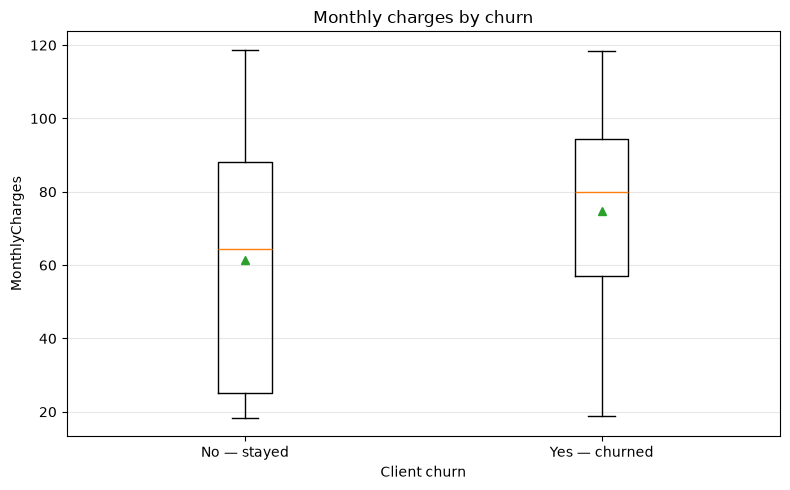

                churned_clients_count  total_monthly_charges  \
Contract                                                       
Month-to-month                   1326               97528.85   
One year                          130               11075.00   
Two year                           39                3312.10   

                mean_monthly_charges  
Contract                              
Month-to-month                 73.55  
One year                       85.19  
Two year                       84.93  
                total_clients  churned_clients_count  churn_rate  \
Contract                                                           
Month-to-month           3102                   1326       42.75   
One year                 1173                    130       11.08   
Two year                 1359                     39        2.87   

                total_monthly_charges_churned  
Contract                                       
Month-to-month                       97528.85  

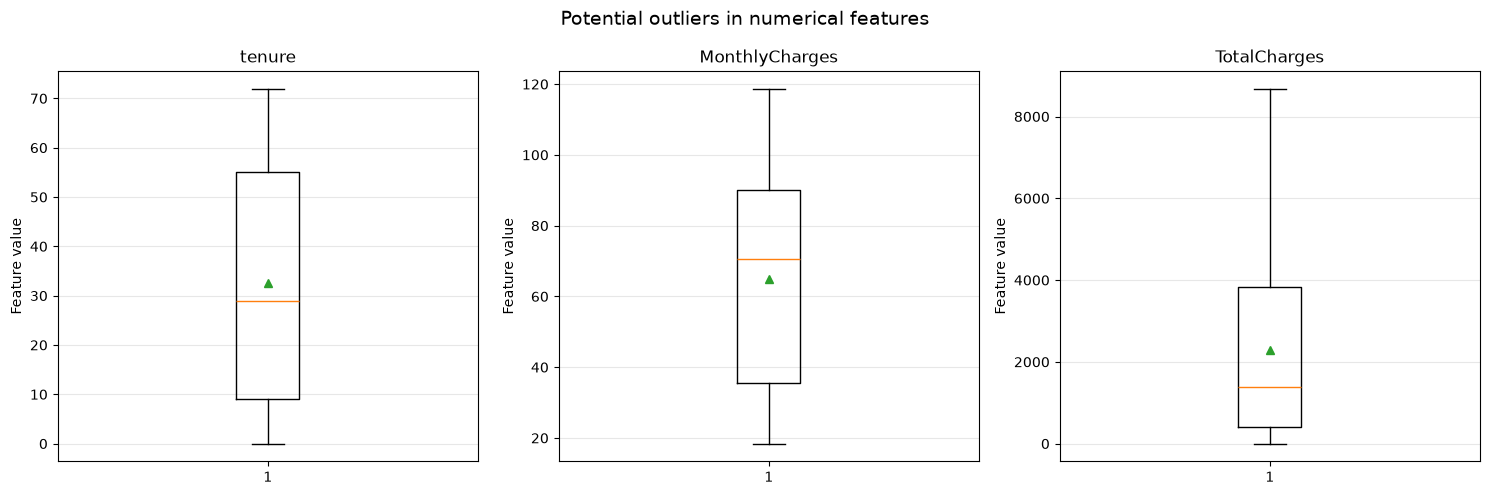

          Feature      Q1       Q3      IQR  Lower bound  Upper bound  \
0          tenure    9.00    55.00    46.00       -60.00       124.00   
1  MonthlyCharges   35.66    90.00    54.34       -45.84       171.51   
2    TotalCharges  402.98  3835.82  3432.85     -4746.30      8985.10   

   Potential outliers count  
0                         0  
1                         0  
2                         0  


,Mean,Std
roc_auc,0.846,0.013
average_precision,0.662,0.019
precision,0.653,0.026
recall,0.543,0.041
f1,0.592,0.030


                  Logistic Regression        DummyClassifier     
                                 Mean    Std            Mean  Std
roc_auc                         0.846  0.013           0.500  0.0
average_precision               0.662  0.019           0.265  0.0
precision                       0.653  0.026           0.000  0.0
recall                          0.543  0.041           0.000  0.0
f1                              0.592  0.030           0.000  0.0
X shape: (5634, 19)
y shape: (5634,)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Missing values in features:
Series([], dtype: int64)
roc_auc: 0.845 +/- 0.010
average_precision: 0.660 +/- 0.023
precision: 0.665 +/- 0.043
recall: 0.513 +/- 0.020
f1: 0.578 +/- 0.024
Fitting 3 folds for each of 6 candidates, totalling 1

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix

# Importing the libraries needed for EDA, pipelines, and model evaluation

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
# Loading the dataset and printing it to immediately assess the structure and potential parsing issues
df
# Checking data types and missing values to quickly spot columns that need transformation
df.info()

df.isna().sum()

df.duplicated().sum()
# Checking for duplicate rows

# Calculating the proportion and absolute count of clients in each class
df["Churn"].value_counts(normalize=True) * 100
df["Churn"].value_counts()

# Target variable distribution
# The dataset has 7 043 clients: 5 174 (73.5%) stayed and 1 869 (26.5%) churned, the classes are imbalanced
# A naive model predicting "No" for everyone would get around 73.5% Accuracy but be useless for the business
# Therefore, accuracy is not enough, I need metrics that evaluate the model's ability to find churned clients such as recall and F1

# Checking the number of rows where TotalCharges contains only spaces
(df["TotalCharges"].str.strip() == "").sum()

# Investigating clients with empty TotalCharges to understand the nature of these missing values
df.loc[df["TotalCharges"].str.strip() == "", ["tenure", "MonthlyCharges", "Churn"]]

# Discovered issue: found 11 empty strings in TotalCharges that pandas did not recognize as NaN
# All these clients have tenure = 0, positive monthly charges, and Churn = No
# This means they just signed up and the total amount hasn't accumulated yet 
# I will replace these empty strings with 0 as this logically reflects the business meaning of the feature 
# But first I need to convert the column to a numeric type

# Stripping leading and trailing spaces
df["TotalCharges"] = df["TotalCharges"].str.strip()
# Converting empty strings to actual missing values (NaN)
df["TotalCharges"] = df["TotalCharges"].replace("", np.nan)
# Converting the remaining values to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])
# Checking the transformation result
df.info()
print("Missing values count:", df["TotalCharges"].isna().sum())

# Data quality check: 11 empty strings are correctly recognized as NaN
# Since all these clients have tenure = 0, I assume the total charges haven't accumulated yet
# Replacing missing values with 0 is justified by business logic, not just random imputation

# Filling the remaining missing values with zeros
# This is an assumption for this dataset; before such imputation it is important to ensure there are no other types of missing values
df = df.fillna(0)

cat_cols = [
    "gender",
    "InternetService",
    "Contract",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "MultipleLines"]

# Printing category frequencies to find typos or unexpected values
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

# Categorical feature check
# Values like "No internet service" reflect the absence of the service and are not data errors
# No obvious typos found, so these features do not require correction at this stage

# Checking the basic statistics of numerical features
df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].describe()

# Checking the number of clients with zero tenure and zero charges
print("Clients with tenure = 0:", (df["tenure"] == 0).sum())
print("Clients with TotalCharges = 0:", (df["TotalCharges"] == 0).sum())
# Checking if these client groups overlap
print("Both values are zero:",
    ((df["tenure"] == 0) & (df["TotalCharges"] == 0)).sum())
# Displaying rows where at least one of the features is zero
display(df.loc[
        (df["tenure"] == 0) | (df["TotalCharges"] == 0),
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# Checking tenure and TotalCharges
# The decision to replace empty values with 0 is confirmed by the fact that with zero tenure the sum couldn't have accumulated yet
# It is important to understand that this is a reasoned assumption about the nature of missing values, not confirmed original amounts

# Checking the uniqueness of client IDs
print("Unique customerID:", df["customerID"].nunique())
print("Duplicate customerID:", df["customerID"].duplicated().sum())

# Checking categories in the remaining features
cat_cols = [
    "Partner",
    "Dependents",
    "PhoneService",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling"
]

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

# Initial data audit summary
# Found 11 empty strings in TotalCharges, replaced with 0 (tenure = 0)
# No obvious errors found among categorical features
# customerID has no duplicates and will be excluded from the model features
# Initial audit is complete, the next step is splitting the data into training and holdout sets

# Separating features from the target variable; excluding customerID as it is just an identifier
x = df.drop(columns = ['customerID','Churn'])
y = df['Churn']

# Keeping 20% of the data for final evaluation and preserving class proportions using stratify=y
# Isolating the test set so it won't participate in EDA, hyperparameter tuning, or model selection
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

# Checking class proportions in the training and test sets to ensure the balance is preserved
print("Train:")
print((y_train.value_counts(normalize=True) * 100).round(2))
print("\nTest:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# Calculating the proportion of each Churn class within each Contract category
ct = pd.crosstab(x_train['Contract'], y_train, normalize='index')
print(ct)

# Churn analysis by contract type
# Hypothesis: clients with month-to-month contracts churn more often
# Result: churn rate is 42.75% for Month-to-month, 11.08% for One year, and 2.87% for Two year
# The data supports the hypothesis, contract type is potentially important for predicting churn
# Next step is to visualize these differences

# Calculating the proportion of churned clients for each contract type
churn_rate = pd.crosstab(x_train["Contract"], y_train, normalize="index")["Yes"] * 100

# Building a bar chart for clarity
plt.figure(figsize=(8, 5))
plt.bar(churn_rate.index, churn_rate.values, color="skyblue", edgecolor="black")

# Formatting the chart
plt.title("Churn rate by contract type")
plt.xlabel("Contract type")
plt.ylabel("Churn rate, %")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

# The churn rate decreases noticeably as the contract term increases
# The observation confirms the hypothesis and indicates the importance of the Contract feature
# Causation, however, is not established

# Setting interval boundaries for tenure grouping, including zero
bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ["0–12", "13–24", "25–36", "37–48", "49–60", "61–72"]
# Binning client tenure into groups
x_train["tenure_group"] = pd.cut(x_train["tenure"], bins=bins, labels=labels)

# Checking the number of clients in each group and the absence of missing values
print(x_train["tenure_group"].value_counts().sort_index())
print("Total clients:", x_train["tenure_group"].notna().sum())
print("Missing values in groups:", x_train["tenure_group"].isna().sum())

ct_tenure_group = pd.crosstab(x_train["tenure_group"], y_train, normalize='index')
print(ct_tenure_group)

# Churn analysis by client tenure
# Hypothesis: clients with short tenure churn more often
# Result: churn rate drops from 47.32% (0-12 months) to 6.81% (61-72 months)
# Client tenure might be an important feature, keeping the tenure feature for modeling

# Calculating the proportion of churned clients for each tenure group
churn_rate = pd.crosstab(x_train["tenure_group"], y_train, normalize="index")["Yes"] * 100

plt.figure(figsize=(8, 5))
plt.bar(churn_rate.index, churn_rate.values, color="skyblue", edgecolor="black")

plt.title('Churn rate by client tenure')
plt.xlabel('Client tenure, months')
plt.ylabel('Churn rate, %')
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

# The churn rate decreases noticeably as tenure increases, the hypothesis is supported by the data

# Combining monthly charges and the target variable
charges_df = pd.DataFrame({"MonthlyCharges": x_train["MonthlyCharges"], "Churn": y_train})

# Comparing monthly charge statistics depending on churn
charges_stats = charges_df.groupby("Churn").agg(
    count=("MonthlyCharges", "count"),
    mean=("MonthlyCharges", "mean"),
    median=("MonthlyCharges", "median"),
    std=("MonthlyCharges", "std"))

charges_stats = charges_stats.round(2)
print(charges_stats)

# Monthly charges analysis
# Hypothesis: clients with higher monthly charges might churn more often
# Result: average MonthlyCharges for churned is 74.86, for stayed is 61.34
# Statistics support the hypothesis, but the distributions overlap

charges_df = pd.DataFrame({"MonthlyCharges": x_train["MonthlyCharges"], "Churn": y_train})

charges_no = charges_df.loc[charges_df["Churn"] == "No", "MonthlyCharges"]
charges_yes = charges_df.loc[charges_df["Churn"] == "Yes", "MonthlyCharges"]

# Building a boxplot to compare distributions
plt.figure(figsize=(8, 5))
plt.boxplot([charges_no, charges_yes], showmeans=True, showfliers=False)

plt.xticks([1, 2], ["No — stayed", "Yes — churned"])
plt.title("Monthly charges by churn")
plt.xlabel("Client churn")
plt.ylabel("MonthlyCharges")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Churned clients have higher mean and median, which aligns with the hypothesis
# However, the overlap in distributions means the groups cannot be separated by MonthlyCharges alone

# Combining contract type, charges, and churn for financial analysis
financial_df = pd.DataFrame({"Contract": x_train["Contract"],
    "MonthlyCharges": x_train["MonthlyCharges"],
    "Churn": y_train})

churned_clients = financial_df[financial_df["Churn"] == "Yes"]

# Calculating financial metrics by contract type among churned clients
financial_stats = churned_clients.groupby("Contract").agg(
    churned_clients_count=("MonthlyCharges", "count"),
    total_monthly_charges=("MonthlyCharges", "sum"),
    mean_monthly_charges=("MonthlyCharges", "mean"))

financial_stats = financial_stats.round(2)
# Sorting by the sum of monthly charges to see the most unprofitable segments
financial_stats = financial_stats.sort_values(
    by="total_monthly_charges",
    ascending=False)
print(financial_stats)

# Financial churn metrics by contract type
# Question: which contract types account for the highest sum of monthly charges from churned clients?
# Result: Month-to-month accounts for 97 528.85, One year for 11 075.00
# Absolute churn count and average payment are different business metrics
# The obtained sums characterize the scale of the problem but are not an estimate of net financial losses

analysis_df = pd.DataFrame({
    "Contract": x_train["Contract"],
    "MonthlyCharges": x_train["MonthlyCharges"],
    "Churn": y_train})

contract_summary = analysis_df.groupby("Contract").agg(
    total_clients=("Churn", "size"),
    churned_clients_count=("Churn", lambda s: (s == "Yes").sum()),
    churn_rate=("Churn", lambda s: (s == "Yes").mean() * 100))

churned_charges = (
    analysis_df[analysis_df["Churn"] == "Yes"]
    .groupby("Contract")["MonthlyCharges"]
    .sum()
    .rename("total_monthly_charges_churned"))

contract_summary = contract_summary.join(churned_charges)
contract_summary["churn_rate"] = contract_summary["churn_rate"].round(2)
contract_summary["total_monthly_charges_churned"] = (contract_summary["total_monthly_charges_churned"].round(2))

contract_summary = contract_summary.sort_values(by="churn_rate", ascending=False)
print(contract_summary)

# Comparing churn and monthly charges
# Question: do contract types with a high churn rate coincide with the highest sum of churned payments?
# Conclusion: Month-to-month is a priority segment for the business as it has both the highest churn rate and the highest volume of payments

# Selecting numerical features to search for potential outliers
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_cols):
    ax.boxplot(x_train[col].dropna(), showmeans=True)
    ax.set_title(col)
    ax.set_ylabel("Feature value")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Potential outliers in numerical features", fontsize=14)
plt.tight_layout()
plt.show()

# Checking for potential outliers via boxplot
# No individual observations found beyond the whiskers 
# The TotalCharges distribution has right skewness but this is not a reason to remove values
# Keeping all observations without additional processing

outlier_results = []

# Calculating IQR boundaries for formal outlier checking
for col in numeric_cols:
    q1 = x_train[col].quantile(0.25)
    q3 = x_train[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers_count = ((x_train[col] < lower_bound) | (x_train[col] > upper_bound)).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Potential outliers count": outliers_count})

outlier_df = pd.DataFrame(outlier_results).round(2)
print(outlier_df)

# Formal IQR check confirms: no observations are outside the boundaries
# No potential outliers but this doesn't rule out skewness issues

# Excluding the temporary tenure_group feature created only for EDA
X_train_model = x_train.drop(
    columns=["tenure_group"],
    errors="ignore").copy()

# Encoding the target variable (No = 0, Yes = 1)
y_train_model = y_train.map({"No": 0, "Yes": 1})

# Checking that all values were successfully converted
assert y_train_model.notna().all(), "Unknown Churn values found"

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"]

# Creating a Pipeline for numerical features (median + scaling)
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

# Creating a Pipeline for categorical features (mode + One-Hot Encoding)
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

# Combining feature processing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)])

# Creating the main Pipeline for Logistic Regression
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))])

# Setting up stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

# Selecting evaluation metrics, the positive class is Churn = 1
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"}

# Evaluating the model using cross_validate 
# This is important: preprocessing is retrained only on the train part of each fold, preventing data leakage
cv_results = cross_validate(
    logistic_pipeline,
    X_train_model,
    y_train_model,
    cv=cv,
    scoring=scoring,
    n_jobs=-1)

# Aggregating the mean metric values and their standard deviations
cv_summary = pd.DataFrame({
    "Mean": {metric: cv_results[f"test_{metric}"].mean()
        for metric in scoring},
    "Std": {metric: cv_results[f"test_{metric}"].std()
        for metric in scoring}})

display(cv_summary.round(3))

# After evaluating on folds, training the Pipeline on the entire X_train
logistic_pipeline.fit(X_train_model, y_train_model)

# Baseline: Logistic Regression
# The model achieved a ROC-AUC of 0.846 and Recall of 0.543, it is capable of ranking clients by churn risk
# At a 0.5 threshold it identifies about 54% of churned clients, practical utility will be compared with DummyClassifier and CatBoost

dummy_scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)}

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_cv_results = cross_validate(
    dummy_model,
    X_train_model,
    y_train_model,
    cv=cv,
    scoring=dummy_scoring,
    n_jobs=-1)

dummy_summary = pd.DataFrame({
    "Mean": {
        metric: dummy_cv_results[f"test_{metric}"].mean()
        for metric in dummy_scoring},
    "Std": {
        metric: dummy_cv_results[f"test_{metric}"].std()
        for metric in dummy_scoring}})

comparison = pd.concat( {"Logistic Regression": cv_summary, "DummyClassifier": dummy_summary}, axis=1)
print(comparison.round(3))

# Comparing Logistic Regression and DummyClassifier
# The naive baseline got a ROC-AUC of 0.500 and zero Precision/Recall/F1 as it always predicts the "No" class
# Logistic regression uses patterns and significantly outperforms the baseline, this is a working starting point

# Using original features without One-Hot Encoding and scaling for CatBoost
# Copies are needed so as not to alter the data prepared for other experiments
X_train_cb = X_train_model.copy()
y_train_cb = y_train_model.copy()

cat_features_cb = X_train_cb.select_dtypes(include=["object", "category", str]).columns.tolist()

print("X shape:", X_train_cb.shape)
print("y shape:", y_train_cb.shape)

print("\nCategorical features:")
print(cat_features_cb)

print("\nMissing values in features:")
print(X_train_cb.isna().sum()[X_train_cb.isna().sum() > 0])

# Creating the first CatBoost configuration with fixed parameters for a fair comparison with Logistic Regression
catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"}

# Evaluating the base CatBoost on the same folds
catboost_scores = cross_validate(
    estimator=catboost_model,
    X=X_train_cb,
    y=y_train_cb,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    params={"cat_features": cat_features_cb},
    return_train_score=False)

for metric in scoring:
    values = catboost_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} +/- {values.std():.3f}")

# Setting hyperparameter ranges for RandomizedSearchCV
# This is a limited search to quickly check a few combinations
param_distributions = {
    "iterations": [300, 500, 700],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [3, 5, 7]}

# Using 3 folds for tuning to save time
cv_tuning = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42)

# Randomly checking 6 combinations, optimizing Average Precision
catboost_search = RandomizedSearchCV(
    estimator=catboost_model,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="average_precision",
    cv=cv_tuning,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True)

catboost_search.fit(
    X_train_cb,
    y_train_cb,
    cat_features=cat_features_cb)

print("Best parameters:")
print(catboost_search.best_params_)
print("\nBest Average Precision on CV:", round(catboost_search.best_score_, 3))

# Creating CatBoost with the found hyperparameters
catboost_tuned = CatBoostClassifier(
    **catboost_search.best_params_,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False)

# Re-evaluating the tuned CatBoost on 5 folds to compare with the baseline
tuned_scores = cross_validate(
    estimator=catboost_tuned,
    X=X_train_cb,
    y=y_train_cb,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    params={"cat_features": cat_features_cb},
    return_train_score=False)

for metric in scoring:
    values = tuned_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

# Tuning improved CatBoost (Average Precision increased from 0.660 to 0.672, ROC-AUC from 0.845 to 0.851)
# Compared to Logistic Regression CatBoost is better in ROC-AUC and Precision but lags in Recall, F1 is roughly the same
# Unconditional advantage is not yet proven, need to evaluate models in terms of a business scenario (selecting K clients)

# Preparing a separate Pipeline for out-of-fold predictions of Logistic Regression
numeric_features = X_train_cb.select_dtypes(include="number").columns.tolist()
categorical_features = [
    col for col in X_train_cb.columns
    if col not in numeric_features]

preprocessor = ColumnTransformer([
    ("num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features),
    ("cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
        categorical_features)])

logreg_oof_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42))])

catboost_tuned = CatBoostClassifier(
    **catboost_search.best_params_,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False)

cv_oof = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

# Function to get out-of-fold probabilities
# This allows comparing client rankings without optimistic bias (the prediction for a row is made by a model that didn't see it)
def get_oof_probabilities(
    estimator,
    X,
    y,
    cv,
    fit_params=None):
    
    oof_proba = np.full(len(X), np.nan)

    for train_idx, valid_idx in cv.split(X, y):
        model = clone(estimator)

        model.fit(
            X.iloc[train_idx],
            y.iloc[train_idx],
            **(fit_params or {}))

        oof_proba[valid_idx] = model.predict_proba(
            X.iloc[valid_idx])[:, 1]

    if np.isnan(oof_proba).any():
        raise ValueError("Predictions not obtained for all rows")

    return oof_proba

# Getting comparable out-of-fold probabilities for both models
lr_oof_proba = get_oof_probabilities(
    logreg_oof_model,
    X_train_cb,
    y_train_cb,
    cv_oof)

catboost_oof_proba = get_oof_probabilities(
    catboost_tuned,
    X_train_cb,
    y_train_cb,
    cv_oof,
    fit_params={"cat_features": cat_features_cb})

# Function to evaluate ranking quality with a fixed budget (K clients)
def ranking_metrics_at_k(y_true, probabilities, k):
    y_true = np.asarray(y_true)

    if not 1 <= k <= len(y_true):
        raise ValueError("K must be between 1 and the number of observations")

    top_k_idx = np.argsort(probabilities)[::-1][:k]

    churn_found = int(y_true[top_k_idx].sum())
    total_churn = int(y_true.sum())

    return {
        "K": k,
        "Churned clients found": churn_found,
        "Precision@K": churn_found / k,
        "Recall@K": churn_found / total_churn}

# Testing a business scenario: the company can handle 300 clients
K = 300

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        **ranking_metrics_at_k(
            y_train_cb, lr_oof_proba, K)},
    {   "Model": "CatBoost tuned",
        **ranking_metrics_at_k(
            y_train_cb, catboost_oof_proba, K)}])

print(results.to_string(index=False))

# Comparing with random selection where Precision equals the overall churn rate
churn_rate = np.mean(y_train_cb)

print(f"\nProportion of Churn = 1 in train set: {churn_rate:.3f}")
print(f"Expected Precision@{K} with random selection: {churn_rate:.3f}")
print(f"Expected Recall@{K} with random selection: {K / len(y_train_cb):.3f}")

# Checking if the advantage holds for different K values
K_values = [100, 200, 300, 500, 1000]

models_proba = {
    "Logistic Regression": lr_oof_proba,
    "CatBoost tuned": catboost_oof_proba}

rows = []

for k in K_values:
    for model_name, probabilities in models_proba.items():
        metrics = ranking_metrics_at_k(
            y_train_cb,
            probabilities,
            k)

        rows.append({
            "Model": model_name,
            **metrics})

ranking_comparison = pd.DataFrame(rows)
print(ranking_comparison.round(3).to_string(index=False))

# Preparing the test set for final evaluation
X_test_model = x_test.copy()
y_test_model = y_test.copy()

X_test_cb = X_test_model.copy()
y_test_cb = y_test_model.copy()

# Converting the target variable to numeric format
unique_targets = set(pd.Series(y_test_cb).dropna().unique())

if unique_targets <= {"No", "Yes"}:
    y_test_cb = y_test_cb.map({"No": 0, "Yes": 1})

y_test_cb = y_test_cb.astype(int)

# Aligning the column order
X_test_cb = X_test_cb[X_train_cb.columns]

print("Test set size:", X_test_cb.shape)
print("\nTarget class distribution:")
print(y_test_cb.value_counts())

# Training the final models on the entire training set
final_lr = clone(logreg_oof_model)
final_lr.fit(
    X_train_cb,
    y_train_cb)

final_catboost = CatBoostClassifier(
    **catboost_search.best_params_,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False)

final_catboost.fit(
    X_train_cb,
    y_train_cb,
    cat_features=cat_features_cb)

print("Both models trained on the full training set")

models = {
    "Logistic Regression": final_lr,
    "CatBoost tuned": final_catboost}

y_test_array = np.asarray(y_test_cb)

# Getting probabilities on the test set
test_probabilities = {
    name: model.predict_proba(X_test_cb)[:, 1]
    for name, model in models.items()}

# Calculating final metrics on the test set, threshold 0.5 is fixed
test_rows = []

for name, probabilities in test_probabilities.items():
    predictions = (probabilities >= 0.5).astype(int)

    test_rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test_array, probabilities),
        "Average Precision": average_precision_score(y_test_array, probabilities),
        "Precision": precision_score(
            y_test_array, predictions, zero_division=0),
        "Recall": recall_score(
            y_test_array, predictions, zero_division=0),
        "F1": f1_score(
            y_test_array, predictions, zero_division=0 )})

test_metrics = pd.DataFrame(test_rows).set_index("Model")
print(test_metrics.round(3))

# Confusion matrix shows the error types of each model at the 0.5 threshold
for name, probabilities in test_probabilities.items():
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\nConfusion matrix: {name}")
    print(
        pd.DataFrame(
            confusion_matrix(
                y_test_array,
                predictions,
                labels=[0, 1]),
            index=["Actual: No", "Actual: Yes"],
            columns=["Predicted: No", "Predicted: Yes"]))

def calculate_top_k_metrics(y_true, probabilities, k):
    y_true = np.asarray(y_true)

    top_k_indices = np.argsort(probabilities)[::-1][:k]

    churn_found = int(y_true[top_k_indices].sum())
    total_churn = int(y_true.sum())

    return {
        "K": k,
        "Churned clients found": churn_found,
        "Precision@K": churn_found / k,
        "Recall@K": churn_found / total_churn}

# Testing business scenarios for different target group sizes on the test set
K_values = [100, 200, 300, 400, 500]

ranking_rows = []

for k in K_values:
    for model_name, probabilities in test_probabilities.items():
        ranking_rows.append({
            "Model": model_name,
            **calculate_top_k_metrics(
                y_test_array,
                probabilities,
                k)})

# The summary table shows how many churned clients made it into the top-K ranking
# This evaluates selection quality but doesn't guarantee the clients can be retained
test_ranking = pd.DataFrame(ranking_rows)

print(test_ranking.round(3).to_string(index=False))